# Nasdaq 01 · Data and point-in-time Nasdaq universe

This repeats the ASX data pipeline for **Nasdaq-listed stocks**, built the same way as the ASX 500:

1. Take **every currently listed Nasdaq common stock** from Nasdaq's official symbol directory (ETFs, warrants, rights, units, preferreds, notes and ADRs removed).
2. Download daily OHLCV, plus the Nasdaq Composite (^IXIC) and Nasdaq-100 (^NDX).
3. Clean returns with the same rules as the ASX and US studies.
4. Each month end, keep the **1,000 most-traded eligible stocks**.

**Survivorship bias.** As with the ASX, the pool is today's listings, so companies that delisted (failed biotechs, dot-com casualties, acquisitions) are missing. Nasdaq has one of the highest delisting rates of any major exchange, so the bias is large. Alpha is measured against an equal-weight universe with the same bias.

In [1]:
import io
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf

pd.set_option("display.width", 200)
DATA = Path("data")
DATA.mkdir(exist_ok=True)

START = "2005-01-01"
BENCHMARKS = ["^IXIC", "^NDX"]
N_UNIVERSE = 1000
MIN_PRICE = 5.0          # US convention: exclude sub-$5 stocks
MIN_HISTORY = 252
SPIKE = np.log(1.5)
DIRECTORY = "https://www.nasdaqtrader.com/dynamic/SymDir/nasdaqlisted.txt"

## 1. Ticker pool

Nasdaq publishes a pipe-delimited directory of every listed security. Keep non-test, non-ETF issues whose security name is a common or ordinary share, and drop ADRs, warrants, rights, units, preferreds and notes.

In [2]:
pool_path = DATA / "ticker_pool.csv"
if not pool_path.exists():
    r = requests.get(DIRECTORY, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    r.raise_for_status()
    df = pd.read_csv(io.StringIO(r.text), sep="|", keep_default_na=False)   # "NA" is a real ticker
    df = df[(df["ETF"] == "N") & (df["Test Issue"] == "N")]
    name = df["Security Name"].fillna("")
    keep = name.str.contains(r"Common Stock|Ordinary Share|Common Shares", case=False)
    drop = name.str.contains(r"Depositary|Warrant|Right|Unit|Preferred|Notes|Debenture", case=False)
    pool = pd.DataFrame({"ticker": df.loc[keep & ~drop, "Symbol"].str.replace(".", "-", regex=False),
                         "name": name[keep & ~drop], "sector": "", "source": "Nasdaq listed"})
    pool.to_csv(pool_path, index=False)
pool = pd.read_csv(pool_path, keep_default_na=False)
print(f"{len(pool)} Nasdaq-listed common stocks")
pool.head()

3154 Nasdaq-listed common stocks


,ticker,name,sector,source
0,AACI,Armada Acquisition Corp. III - Class A Ordinar...,,Nasdaq listed
1,AACO,Abony Acquisition Corp. I - Class A Ordinary S...,,Nasdaq listed
2,AACP,Apogee Acquisition Corp - Class A Ordinary Shares,,Nasdaq listed
3,AAL,"American Airlines Group, Inc. - Common Stock",,Nasdaq listed
4,AAME,Atlantic American Corporation - Common Stock,,Nasdaq listed


## 2. Download

In [3]:
def download(tickers, batch=250):
    frames = []
    for i in range(0, len(tickers), batch):
        chunk = tickers[i:i + batch]
        for attempt in range(3):
            try:
                d = yf.download(chunk, start=START, auto_adjust=False, actions=False,
                                progress=False, threads=True, group_by="column")
                break
            except Exception as e:
                print("retry", i, e)
                time.sleep(5)
        d = d.stack(level=1, future_stack=True).rename_axis(["date", "ticker"])
        frames.append(d.dropna(how="all"))
        print(f"{i + len(chunk)}/{len(tickers)}")
    out = pd.concat(frames)
    out.columns = [c.lower().replace(" ", "_") for c in out.columns]
    return out


if not (DATA / "ohlcv.parquet").exists():
    download(sorted(pool["ticker"])).to_parquet(DATA / "ohlcv.parquet")
    download(BENCHMARKS).to_parquet(DATA / "benchmarks.parquet")
raw = pd.read_parquet(DATA / "ohlcv.parquet")
got = set(raw.index.get_level_values("ticker"))
print(f"{len(got)} of {len(pool)} tickers have Yahoo data")
pool.assign(has_data=pool["ticker"].isin(got)).groupby("source")["has_data"].agg(["sum", "count"])

250/3154


500/3154


750/3154


1000/3154


1250/3154


...

3000/3154


3154/3154


2/2


3154 of 3154 tickers have Yahoo data


,sum,count
source,,
Nasdaq listed,3154,3154


Nearly all listed stocks have data. Many are recent listings (IPOs and SPAC mergers since 2020) with short histories, so they only enter the universe once they have a year of trading.

## 3. Cleaning

The rules are the same as for the ASX (see the ASX notebook 01 for the reasoning):
* broken adjustment factors (a big adjusted move the raw close doesn't share) are masked;
* bad prints (a jump of more than 50% that mostly reverses the next day) are masked on both days;
* moves beyond +400% or −80% in a day are masked;
* returns on stale (zero-volume) days are masked;
* high and low are put on the adjusted scale and forced to bracket the close.

In [4]:
def clean_returns(adj, close):
    lr = np.log(adj).diff()
    raw_lr = np.log(close).diff()
    lr = lr.mask((lr.abs() > SPIKE) & ((lr - raw_lr).abs() > SPIKE))
    nxt = lr.shift(-1)
    spike = (lr.abs() > SPIKE) & (np.sign(lr) == -np.sign(nxt)) & (nxt.abs() > 0.7 * lr.abs())
    lr = lr.mask(spike | spike.shift(1, fill_value=False))
    lr = lr.mask(lr.abs() > np.log(5))
    return np.expm1(lr)


wide = {c: raw[c].unstack() for c in ["adj_close", "close", "high", "low", "volume"]}
close = wide["close"].where(wide["close"] > 0)
adj = wide["adj_close"].where(wide["adj_close"] > 0)
factor = adj / close
high = np.maximum(wide["high"].where(wide["high"] > 0) * factor, adj)
low = np.minimum(wide["low"].where(wide["low"] > 0) * factor, adj)
vol = wide["volume"].fillna(0)
traded = vol > 0
ret = clean_returns(adj, close).where(traded | traded.shift(1, fill_value=False))
masked = int((ret.isna() & adj.notna() & adj.shift(1).notna()).sum().sum())
print(f"{adj.shape[1]} stocks, {adj.shape[0]} days; returns masked by cleaning: {masked:,}")

3154 stocks, 5477 days; returns masked by cleaning: 331,546


## 4. Point-in-time universe

At each month end, a stock is eligible if it has at least 252 days of history, a raw close of at least \$5, and a 63-day median traded value (needing at least 40 traded days). The top 1,000 by traded value are members for the following month.

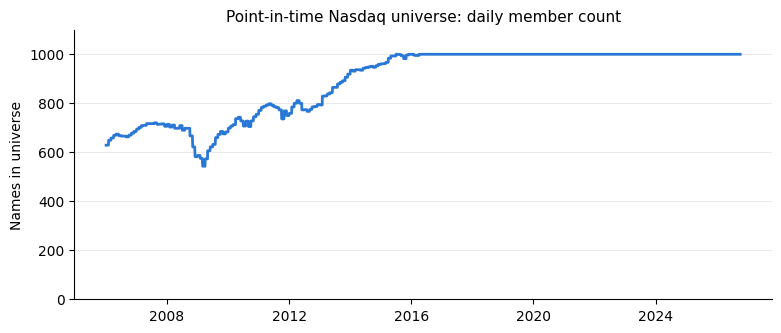

date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
avg members,665.0,712.0,682.0,627.0,725.0,777.0,784.0,862.0,944.0,986.0,...,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0


In [5]:
dollar_vol = (close * vol).where(traded)
adv = dollar_vol.rolling(63, min_periods=40).median()
history = adj.notna().cumsum()
month_end = adj.index.to_series().groupby(adj.index.to_period("M")).max()
elig = (history >= MIN_HISTORY) & (close >= MIN_PRICE) & adv.notna()
rank = adv.where(elig).loc[month_end.values].rank(axis=1, ascending=False)
member = (rank <= N_UNIVERSE).reindex(adj.index).shift(1)
member = member.astype("float").ffill().fillna(0).astype(bool)

counts = member.sum(axis=1).loc["2006":]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(counts.index, counts.values, color="#2a78d6", lw=2)
ax.set_ylim(0, 1100)
ax.set_ylabel("Names in universe")
ax.set_title("Point-in-time Nasdaq universe: daily member count", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
plt.show()
counts.groupby(counts.index.year).mean().round(0).to_frame("avg members").T

The count climbs over time for the same reason as on the ASX: fewer of today's survivors existed, or were big and liquid enough, in earlier years. For Nasdaq the effect is strong because so many of today's listings are recent.

## 5. Benchmarks and save

In [6]:
sector = pool.set_index("ticker")["sector"]
bench = pd.read_parquet(DATA / "benchmarks.parquet")["adj_close"].unstack()
bench_ret = bench.pct_change(fill_method=None).reindex(adj.index)
d = dict(adj=adj, high=high, low=low, close=close, volume=vol, ret=ret, adv=adv,
         member=member, sector=sector.reindex(adj.columns), bench_ret=bench_ret)
pd.to_pickle(d, DATA / "clean.pkl")
print(f"members ever: {member.any().sum()}; benchmarks: {list(bench_ret.columns)}")

members ever: 2081; benchmarks: ['^IXIC', '^NDX']
